# Overview
> **Chuyển đổi từ `5. Others/2_obj_detection.ipynb` sang PyTorch (Nạp dữ liệu thật từ `car_data.zip` & phát hiện trên `test.jpg`)**
- Input: Ảnh RGB 64x64 (`vehicles` = +1, `non-vehicles` = -1).
- Suy luận FCN tạo Heatmap & vẽ Bounding Box trực tiếp trên `test.jpg`.


In [1]:
import zipfile
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# (1) Data (Đọc thật `vehicles/` & `non-vehicles/` từ `car_data.zip`)


In [2]:
zip_path = Path('../../sample/examples/5. Others/car_data.zip')
X_list, Y_list = [], []
with zipfile.ZipFile(zip_path, 'r') as zf:
    veh = sorted([n for n in zf.namelist() if n.startswith('data/obj_detection/vehicles/') and n.endswith('.png')])
    non = sorted([n for n in zf.namelist() if n.startswith('data/obj_detection/non-vehicles/') and n.endswith('.png')])
    for name in np.random.choice(veh, size=500, replace=False):
        with zf.open(name) as fp:
            X_list.append(np.array(Image.open(fp).convert('RGB').resize((64, 64)), dtype=np.float32).transpose(2, 0, 1))
            Y_list.append(1.0)
    for name in np.random.choice(non, size=500, replace=False):
        with zf.open(name) as fp:
            X_list.append(np.array(Image.open(fp).convert('RGB').resize((64, 64)), dtype=np.float32).transpose(2, 0, 1))
            Y_list.append(-1.0)

X = np.array(X_list, dtype=np.float32)
Y = np.array(Y_list, dtype=np.float32)
perm = np.random.permutation(len(X))
X, Y = X[perm], Y[perm]
split = int(0.7 * len(X))
train_loader = DataLoader(TensorDataset(torch.tensor(X[:split]), torch.tensor(Y[:split]).view(-1, 1, 1, 1)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(X[split:]), torch.tensor(Y[split:]).view(-1, 1, 1, 1)), batch_size=64, shuffle=False)
print(f'Train: {split} | Test: {len(X) - split}')


Train: 700 | Test: 300


# (2) Declare Fully Convolutional Model (`CarDetectorCNN`)


In [3]:
class CarDetectorCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 10, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(10, 10, 3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool2d(8, 8), nn.Dropout2d(0.25),
            nn.Conv2d(10, 128, 8, padding=0), nn.ReLU(inplace=True),
            nn.Dropout2d(0.5),
            nn.Conv2d(128, 1, 1, padding=0), nn.Tanh()
        )
    def forward(self, x):
        return self.net(x / 127.5 - 1.0)

model = CarDetectorCNN().to(device)
print(model)


CarDetectorCNN(
  (net): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=8, stride=8, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout2d(p=0.25, inplace=False)
    (6): Conv2d(10, 128, kernel_size=(8, 8), stride=(1, 1))
    (7): ReLU(inplace=True)
    (8): Dropout2d(p=0.5, inplace=False)
    (9): Conv2d(128, 1, kernel_size=(1, 1), stride=(1, 1))
    (10): Tanh()
  )
)


# (3) Train defined model


In [4]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
for ep in range(1, 11):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
    model.eval()
    te_loss, correct = 0.0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            out = model(xb.to(device))
            te_loss += criterion(out, yb.to(device)).item() * len(xb)
            correct += ((out > 0).float() == (yb.to(device) > 0).float()).sum().item()
    print(f'Epoch {ep:02d} | Test MSE: {te_loss/(len(X)-split):.4f} | Test Acc: {correct/(len(X)-split)*100:.2f}%')

torch.save(model.state_dict(), 'localize.pt')


Epoch 01 | Test MSE: 0.8878 | Test Acc: 51.67%


Epoch 02 | Test MSE: 0.7387 | Test Acc: 71.67%


Epoch 03 | Test MSE: 0.5066 | Test Acc: 87.00%


Epoch 04 | Test MSE: 0.3832 | Test Acc: 89.67%


Epoch 05 | Test MSE: 0.3479 | Test Acc: 87.67%


Epoch 06 | Test MSE: 0.2910 | Test Acc: 90.33%


Epoch 07 | Test MSE: 0.2948 | Test Acc: 88.67%


Epoch 08 | Test MSE: 0.2603 | Test Acc: 93.00%


Epoch 09 | Test MSE: 0.3511 | Test Acc: 89.00%


Epoch 10 | Test MSE: 0.2302 | Test Acc: 93.67%


# (4) Evaluate on `test.jpg` using `locate()`


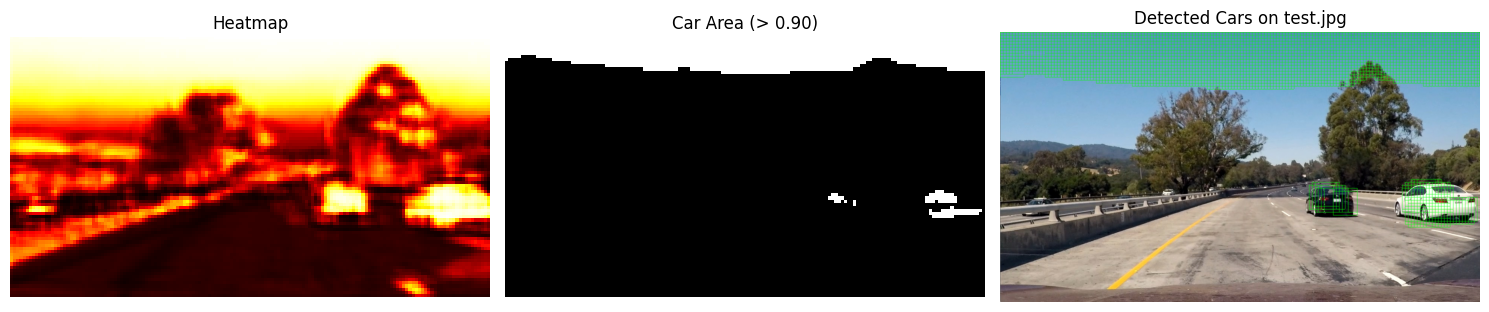

In [5]:
heatmodel = CarDetectorCNN().to(device)
heatmodel.load_state_dict(torch.load('localize.pt', weights_only=True))
heatmodel.eval()

def locate(threshold=0.90):
    data = np.array(Image.open('test.jpg').convert('RGB'), dtype=np.uint8)
    inp = torch.tensor(data.transpose(2, 0, 1), dtype=torch.float32, device=device).unsqueeze(0)
    with torch.no_grad():
        hm = heatmodel(inp).squeeze().cpu().numpy()
    sel_hm = hm > threshold
    yy, xx = np.where(sel_hm)
    annotated = data.copy()
    h_img, w_img, _ = annotated.shape
    for j, i in zip(yy, xx):
        y0, y1 = min(j*8, h_img-1), min(j*8+64, h_img-1)
        x0, x1 = min(i*8, w_img-1), min(i*8+64, w_img-1)
        annotated[y0:y1, x0] = (0, 255, 0); annotated[y0:y1, x1] = (0, 255, 0)
        annotated[y0, x0:x1] = (0, 255, 0); annotated[y1, x0:x1] = (0, 255, 0)
    return hm, sel_hm, annotated

hm, sel_hm, annotated = locate(threshold=0.90)
Path('localize.pt').unlink(missing_ok=True)

plt.figure(figsize=(15, 4))
plt.subplot(131); plt.title('Heatmap'); plt.imshow(hm, cmap='hot'); plt.axis('off')
plt.subplot(132); plt.title('Car Area (> 0.90)'); plt.imshow(sel_hm, cmap='gray'); plt.axis('off')
plt.subplot(133); plt.title('Detected Cars on test.jpg'); plt.imshow(annotated); plt.axis('off')
plt.tight_layout(); plt.show()
